##### STEP 1: download the files

In [5]:
!python src/cascade_data/cli.py download

DS01-OGB1-m-V1: 1 selected, 0 to fetch (0.0 B)
DS02-OGB1-2-m-V1: 1 selected, 0 to fetch (0.0 B)
DS03-Cal520-m-S1: 1 selected, 0 to fetch (0.0 B)
DS04-OGB1-zf-pDp: 1 selected, 0 to fetch (0.0 B)
DS05-Cal520-zf-pDp: 1 selected, 0 to fetch (0.0 B)
DS06-GCaMP6f-zf-aDp: 1 selected, 0 to fetch (0.0 B)
DS07-GCaMP6f-zf-dD: 1 selected, 0 to fetch (0.0 B)
DS08-GCaMP6f-zf-OB: 1 selected, 0 to fetch (0.0 B)
DS09-GCaMP6f-m-V1: 1 selected, 0 to fetch (0.0 B)
DS10-GCaMP6f-m-V1-neuropil-corrected: 1 selected, 0 to fetch (0.0 B)
DS11-GCaMP6f-m-V1-neuropil-corrected: 1 selected, 0 to fetch (0.0 B)
DS12-GCaMP6s-m-V1-neuropil-corrected: 1 selected, 0 to fetch (0.0 B)
DS13-GCaMP6s-m-V1-neuropil-corrected: 1 selected, 0 to fetch (0.0 B)
DS14-GCaMP6s-m-V1: 1 selected, 0 to fetch (0.0 B)
DS15-GCaMP6s-m-V1: 1 selected, 0 to fetch (0.0 B)
DS16-GCaMP6s-m-V1: 1 selected, 0 to fetch (0.0 B)
DS17-GCaMP5k-m-V1: 1 selected, 0 to fetch (0.0 B)
DS18-R-CaMP-m-CA3: 1 selected, 0 to fetch (0.0 B)
DS19-R-CaMP-m-S1: 1 selec

In [19]:
from loader import *
import pandas as pd


In [54]:
%run src/cascade_data/cli.py --root data download DS01-OGB1-m-V1 --limit 50

DS01-OGB1-m-V1: 21 selected, 20 to fetch (1.3 MB)
  -> CAttached_Theis16_set2_OGB_V1_cell_19_mini.mat (33.1 KB)
  -> CAttached_Theis16_set2_OGB_V1_cell_17_mini.mat (37.3 KB)
  -> CAttached_Theis16_set2_OGB_V1_cell_20_mini.mat (44.0 KB)
  -> CAttached_Theis16_set2_OGB_V1_cell_9_mini.mat (45.5 KB)
  -> CAttached_Theis16_set2_OGB_V1_cell_12_mini.mat (52.2 KB)
  -> CAttached_Theis16_set2_OGB_V1_cell_6_mini.mat (52.5 KB)
  -> CAttached_Theis16_set2_OGB_V1_cell_1_mini.mat (54.1 KB)
  -> CAttached_Theis16_set2_OGB_V1_cell_16_mini.mat (55.9 KB)
  -> CAttached_Theis16_set2_OGB_V1_cell_3_mini.mat (60.3 KB)
  -> CAttached_Theis16_set2_OGB_V1_cell_15_mini.mat (67.9 KB)
  -> CAttached_Theis16_set2_OGB_V1_cell_5_mini.mat (72.2 KB)
  -> CAttached_Theis16_set2_OGB_V1_cell_8_mini.mat (74.8 KB)
  -> CAttached_Theis16_set2_OGB_V1_cell_7_mini.mat (76.3 KB)
  -> CAttached_Theis16_set2_OGB_V1_cell_4_mini.mat (77.6 KB)
  -> CAttached_Theis16_set2_OGB_V1_cell_10_mini.mat (79.2 KB)
  -> CAttached_Theis16_set2_

In [35]:
##Maybe create a function for more modular code bruh
loaded = load_recordings_from_file("data/raw/DS01-OGB1-m-V1/CAttached_Theis16_set2_OGB_V1_cell_21_mini.mat")
r=loaded[0]

df=pd.DataFrame({"time(s)":r["t"],"dff":r["dff"]})
spikes=pd.DataFrame({"spike(s)":r["spikes"]})

In [56]:
from pathlib import Path
from baseline_model import write_config, train_model

name = "OGB_2"
folder = Path("models") / name

folder.mkdir(parents=True,exist_ok=True)

write_config(dict(
    model_name=name,
    training_datasets=["DS01-OGB1-m-V1"],
    sampling_rate=7.5,
    smoothing=0.2,
    noise_levels=[5],
    dense_expansion=30,
    nr_of_epochs=10,
    ensemble_size=1,
    batch_size=8192,
), folder / "config.yaml")

train_model(name, model_folder="models", ground_truth_folder="data/raw")

Used configuration for model fitting (file /Users/giovanni/Desktop/ML_Project_2/models/OGB_2/config.yaml):

model_name:	OGB_2
sampling_rate:	7.5
training_datasets:	['DS01-OGB1-m-V1']
placeholder_1:	0
noise_levels:	[5]
placeholder_2:	0
smoothing:	0.2
causal_kernel:	0
windowsize:	64
before_frac:	0.5
filter_sizes:	[31, 19, 5]
filter_numbers:	[30, 40, 50]
dense_expansion:	30
loss_function:	mean_squared_error
optimizer:	Adagrad
nr_of_epochs:	10
ensemble_size:	1
batch_size:	8192
training_finished:	No
verbose:	1


Models will be saved into this folder: /Users/giovanni/Desktop/ML_Project_2/models/OGB_2
Fitting a total of 1 models:
data/raw/DS01-OGB1-m-V1

Fitting model 1 with noise level 5 (total 1 out of 1).
Epoch 1/10


2026-11-21 09:40:46.024153: E tensorflow/core/grappler/optimizers/meta_optimizer.cc:961] PluggableGraphOptimizer failed: INVALID_ARGUMENT: Failed to deserialize the `graph_buf`.


480/480 ━━━━━━━━━━━━━━━━━━━━ 90s 183ms/step - loss: 0.3357
Epoch 2/10
480/480 ━━━━━━━━━━━━━━━━━━━━ 88s 184ms/step - loss: 0.2951
Epoch 3/10
480/480 ━━━━━━━━━━━━━━━━━━━━ 89s 185ms/step - loss: 0.2732
Epoch 4/10
480/480 ━━━━━━━━━━━━━━━━━━━━ 87s 182ms/step - loss: 0.2683
Epoch 5/10
480/480 ━━━━━━━━━━━━━━━━━━━━ 92s 192ms/step - loss: 0.2665
Epoch 6/10
480/480 ━━━━━━━━━━━━━━━━━━━━ 87s 182ms/step - loss: 0.2644
Epoch 7/10
480/480 ━━━━━━━━━━━━━━━━━━━━ 88s 183ms/step - loss: 0.2634
Epoch 8/10
480/480 ━━━━━━━━━━━━━━━━━━━━ 88s 182ms/step - loss: 0.2625
Epoch 9/10
480/480 ━━━━━━━━━━━━━━━━━━━━ 87s 182ms/step - loss: 0.2618
Epoch 10/10
480/480 ━━━━━━━━━━━━━━━━━━━━ 87s 182ms/step - loss: 0.2608


Saved model: Model_NoiseLevel_5_Ensemble_0.h5


Done!
Runtime: 15 min


In [60]:
from baseline_model import predict
from scipy.ndimage import gaussian_filter1d
path = "data/val/CAttached_OGB_pDp_190125_Fish1_cell3_mini.mat"
rec = load_recordings_from_file(path)[0]
pred = predict("OGB_retrained", rec["dff"], model_folder="models", verbosity=0)[0]

# Count spikes per frame, then smooth like during training
t = rec["t"]
dt = 1 / 7.5
bins = np.r_[t, t[-1] + dt] - dt / 2
counts = np.histogram(rec["spikes"], bins=bins)[0]
target = gaussian_filter1d(counts.astype(float), sigma=0.2 * 7.5)

# Score only the frames with predictions
valid = np.isfinite(pred)
y, y_hat = target[valid], pred[valid]
print(f"MSE: {np.mean((y - y_hat)**2):.5f}")
print(f"Pearson r: {np.corrcoef(y, y_hat)[0, 1]:.3f}")

2026-11-21 09:59:42.022637: E tensorflow/core/grappler/optimizers/meta_optimizer.cc:961] PluggableGraphOptimizer failed: INVALID_ARGUMENT: Failed to deserialize the `graph_buf`.


Spike rate inference done.
MSE: 0.01537
Pearson r: 0.784


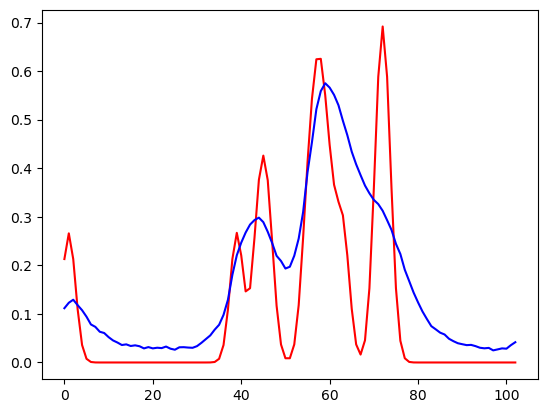

In [61]:
import matplotlib.pyplot as plt

plt.plot(target[valid],c="red")
plt.plot( pred[valid],c="blue")